# Axis Max Life: App Launch Impact Analysis
**Question:** Did the mobile app launch on 2 March 2025 increase revenue?

| # | Section |
|---|---|
| 1 | Setup and data loading |
| 2 | Data audit |
| 3 | Outliers |
| 4 | Daily table |
| 5 | Hypotheses |
| 6 | Descriptive statistics |
| 7 | Hypothesis tests |
| 8 | Confidence intervals |
| 9 | Regression |
| 10 | Sustained lift or spike? |
| 11 | Summary of findings |
| 12 | Recommendations |
| 13 | Methodology note |
| 14 | Excel export |

## 1. Setup and data loading

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.float_format', '{:,.2f}'.format)
LAUNCH = pd.Timestamp('2025-03-02')

In [2]:
# In Colab this opens an upload box; elsewhere it reads the local file
try:
    from google.colab import files
    DATA_PATH = list(files.upload().keys())[0]
except ImportError:
    DATA_PATH = 'app_launch_impact_dataset_1.csv'

raw = pd.read_csv(DATA_PATH, parse_dates=['date'])
raw.shape

(5000, 22)

## 2. Data audit

In [3]:
# Does each total equal website + app?
for m in ['revenue', 'visits', 'conversions']:
    ok = np.isclose(raw[f'total_{m}'], raw[f'website_{m}'] + raw[f'app_{m}']).all()
    print(f'{m:12s} total = website + app: {ok}')

revenue      total = website + app: True
visits       total = website + app: True
conversions  total = website + app: True


In [4]:
# Rows per date
raw.groupby('date').size().value_counts()

42    119
2       1
Name: count, dtype: int64

119 dates have 42 rows each, but **30 Apr 2025 has only 2 rows**. In daily totals it would look like a 95% crash, so it is dropped.

In [5]:
df = raw[raw['date'] != '2025-04-30'].copy()
df['period'] = np.where(df['date'] >= LAUNCH, 'Post', 'Pre')
df['post'] = (df['period'] == 'Post').astype(int)
df['period'].value_counts()

period
Pre     2520
Post    2478
Name: count, dtype: int64

In [6]:
# Missing values
df.isna().sum()[lambda s: s > 0]

avg_policy_value_app    2520
dtype: int64

In [7]:
# App columns before launch should all be 0
app_cols = ['app_visits', 'app_conversions', 'app_revenue', 'app_downloads',
            'active_app_users', 'app_session_duration_avg', 'app_crashes', 'marketing_spend_app']
df.loc[df['period'] == 'Pre', app_cols].max()

app_visits                 0.00
app_conversions            0.00
app_revenue                0.00
app_downloads              0.00
active_app_users           0.00
app_session_duration_avg   0.00
app_crashes                7.00
marketing_spend_app        0.00
dtype: float64

**Findings**
- Totals add up correctly in every row.
- `avg_policy_value_app` is blank only before launch, which is expected.
- `app_crashes` is non-zero before the app existed, so it is **not used** in the analysis.
- `is_holiday` varies within a single date, so each of the 42 daily rows is treated as a separate segment (e.g. a region).

## 3. Outliers (IQR rule, per period)

In [8]:
def iqr_outliers(x):
    q1, q3 = x.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return pd.Series({'lower': lo, 'upper': hi, 'n_low': (x < lo).sum(), 'n_high': (x > hi).sum(),
                      'pct': ((x < lo) | (x > hi)).mean() * 100})

df.groupby('period')['total_revenue'].apply(iqr_outliers).unstack()

,lower,upper,n_low,n_high,pct
period,,,,,
Post,"33,323.27","185,019.34",1.00,21.00,0.89
Pre,"-1,447.63","98,525.19",0.00,26.00,1.03


About **1% of rows** in each period are outliers, almost all on the high side (high-value policies). They are real sales, so they are **kept**. They also have little effect on the main tests: each daily total adds up 42 rows, and the Mann–Whitney test in Section 7 uses ranks, which extreme values cannot dominate.

## 4. Daily table (119 days)

Flows (revenue, visits, conversions, spend) are **summed**; flags are **averaged** (share of rows). Ratios are calculated afterwards as **sum ÷ sum**, so large and small rows are weighted correctly.

In [9]:
flows = ['total_revenue', 'website_revenue', 'app_revenue',
         'total_visits', 'website_visits', 'app_visits',
         'total_conversions', 'website_conversions', 'app_conversions',
         'marketing_spend_website', 'marketing_spend_app']

daily = (df.groupby(['date', 'period', 'post'])
           .agg(**{c: (c, 'sum') for c in flows},
                promo_share=('promo_active', 'mean'),
                holiday_share=('is_holiday', 'mean'),
                day_of_week=('day_of_week', 'first'))
           .reset_index())

daily['total_spend']   = daily['marketing_spend_website'] + daily['marketing_spend_app']
daily['conv_rate_pct'] = daily['total_conversions'] / daily['total_visits'] * 100
daily['roas']          = daily['total_revenue'] / daily['total_spend']
daily['apv_total']     = daily['total_revenue'] / daily['total_conversions']
daily['apv_website']   = daily['website_revenue'] / daily['website_conversions']
daily['apv_app']       = daily['app_revenue'] / daily['app_conversions'].replace(0, np.nan)
daily['days_since_launch'] = (daily['date'] - LAUNCH).dt.days

assert len(daily) == 119
daily['period'].value_counts()

period
Pre     60
Post    59
Name: count, dtype: int64

## 5. Hypotheses
- **Metric:** mean daily total revenue
- **H₀:** the app did **not increase** revenue (μ_post ≤ μ_pre)
- **H₁:** the app **increased** revenue (μ_post > μ_pre)
- **α = 0.05, one-tailed**, because leadership asked specifically about an increase. The direction was set before looking at results.

## 6. Descriptive statistics

In [10]:
metrics = ['total_revenue', 'website_revenue', 'app_revenue', 'total_visits', 'website_visits',
           'total_conversions', 'conv_rate_pct', 'apv_total', 'apv_website', 'apv_app',
           'total_spend', 'roas', 'promo_share', 'holiday_share']

mean = daily.groupby('period')[metrics].mean().T[['Pre', 'Post']]
mean['pct_change'] = (mean['Post'] / mean['Pre'].replace(0, np.nan) - 1) * 100
cv = (daily.groupby('period')[metrics].std() / daily.groupby('period')[metrics].mean()).T
mean['CV_pre'], mean['CV_post'] = cv['Pre'], cv['Post']
mean

period,Pre,Post,pct_change,CV_pre,CV_post
total_revenue,"2,068,224.06","4,629,866.37",123.86,0.10,0.05
website_revenue,"2,068,224.06","2,075,667.21",0.36,0.10,0.10
app_revenue,0.00,"2,554,199.16",NaN,NaN,0.05
total_visits,"9,693.93","17,200.37",77.43,0.08,0.05
website_visits,"9,693.93","9,653.63",-0.42,0.08,0.09
total_conversions,417.12,905.44,117.07,0.09,0.05
conv_rate_pct,4.31,5.27,22.33,0.05,0.04
apv_total,"4,957.75","5,114.54",3.16,0.03,0.02
apv_website,"4,957.75","5,000.06",0.85,0.03,0.02
apv_app,NaN,"5,211.49",NaN,NaN,0.02


- Mean daily revenue rose **+124%** (₹20.7L → ₹46.3L); the app adds about ₹25.5L per day.
- **Website revenue is flat (+0.4%)**, so the app's revenue comes on top of website sales.
- Conversion rate is up **+22%** (4.3% → 5.3%) and average policy value is up **+3%**.
- Promotions and holidays are balanced (−3% and −4%). **Marketing spend rose 76%**, but ROAS rose 27%, so revenue grew much faster than spend.
- Day-to-day swings stayed about the same in rupees (std ≈ ₹2.0L → ₹2.2L), so **relative to its size** revenue is more stable (CV 0.10 → 0.05).

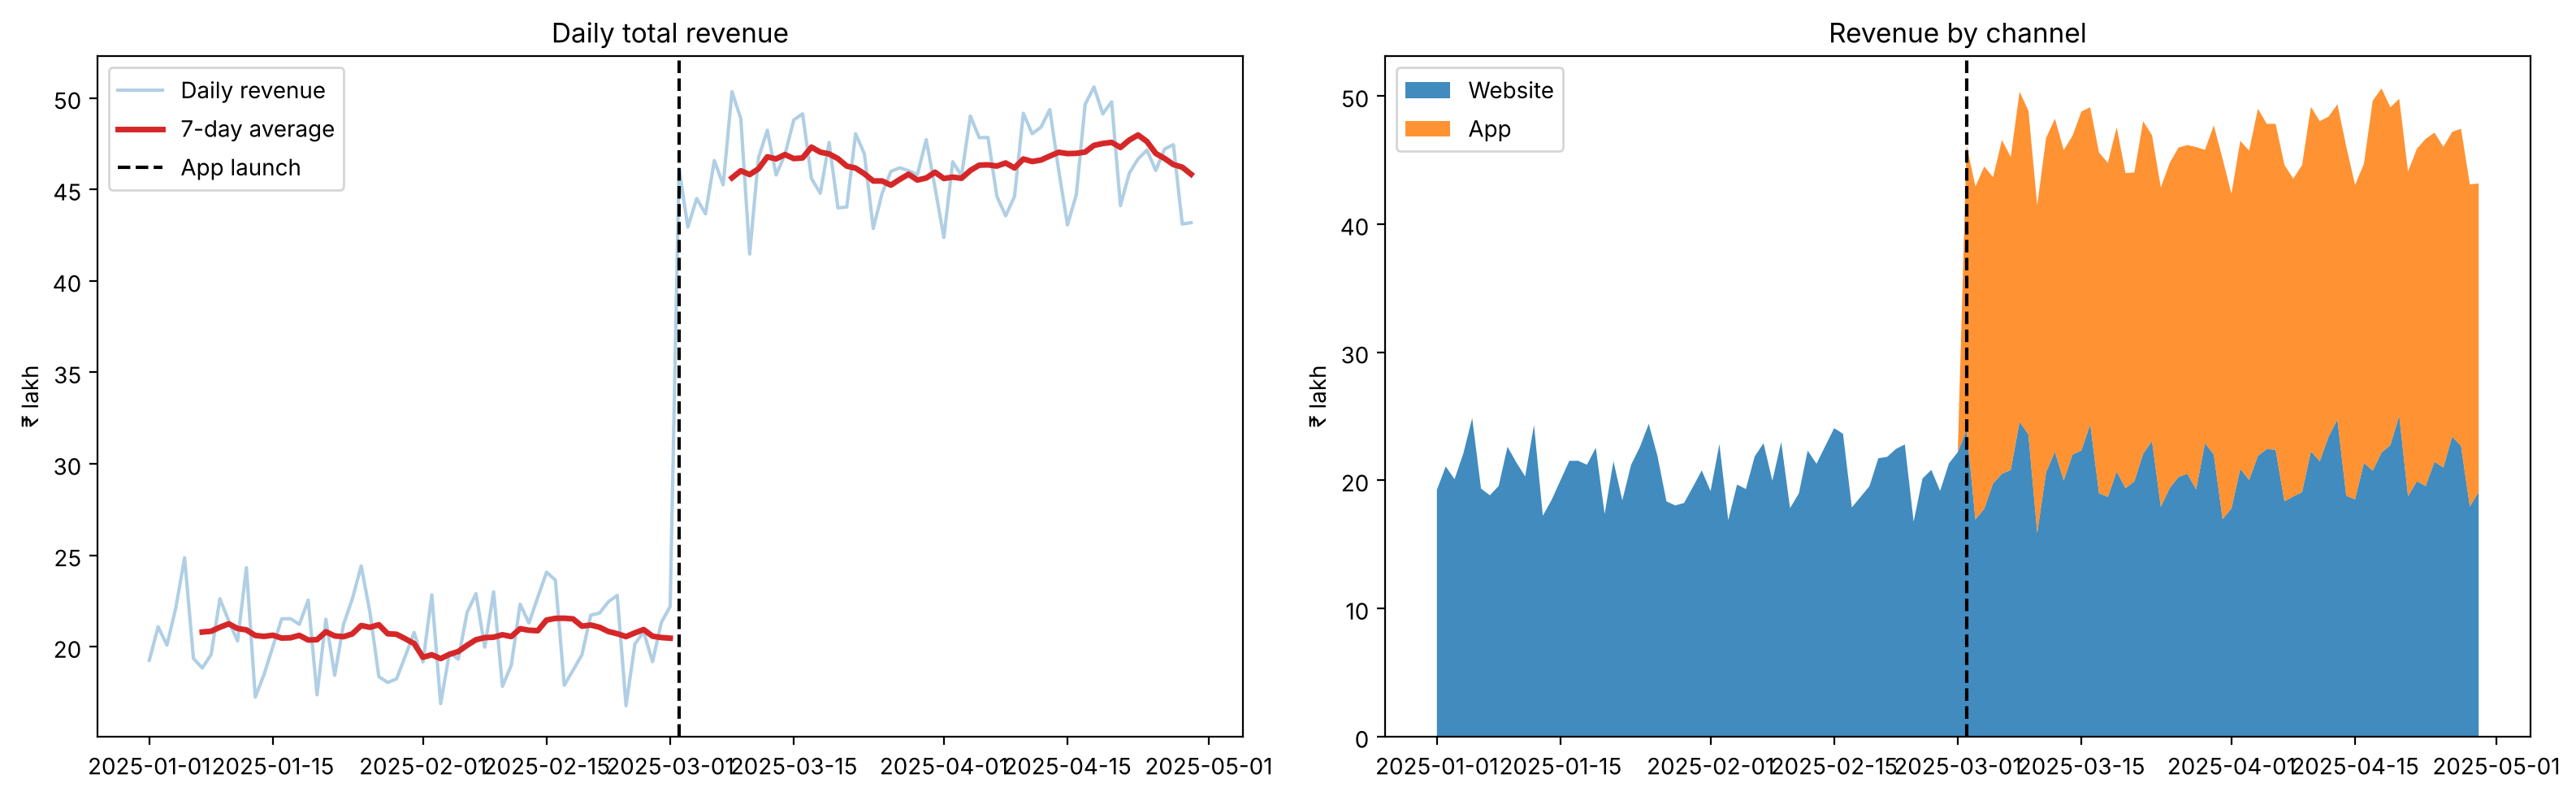

In [11]:
pre  = daily.loc[daily['period'] == 'Pre',  'total_revenue']
post = daily.loc[daily['period'] == 'Post', 'total_revenue']

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
d = daily.copy()
d['rolling_7d'] = d.groupby('period')['total_revenue'].transform(lambda s: s.rolling(7).mean())
ax[0].plot(d['date'], d['total_revenue'] / 1e5, alpha=0.35, label='Daily revenue')
for p in ['Pre', 'Post']:
    s = d[d['period'] == p]
    ax[0].plot(s['date'], s['rolling_7d'] / 1e5, color='tab:red', lw=2.5,
               label='7-day average' if p == 'Pre' else None)
ax[0].axvline(LAUNCH, ls='--', color='black', label='App launch')
ax[0].set(title='Daily total revenue', ylabel='₹ lakh'); ax[0].legend()

ax[1].stackplot(d['date'], d['website_revenue'] / 1e5, d['app_revenue'] / 1e5,
                labels=['Website', 'App'], alpha=0.85)
ax[1].axvline(LAUNCH, ls='--', color='black')
ax[1].set(title='Revenue by channel', ylabel='₹ lakh'); ax[1].legend(loc='upper left')
plt.tight_layout(); plt.show()

Revenue steps up immediately at launch and holds at the new level. The website layer stays at the same height; the app layer sits on top.

In [12]:
post_days = daily[daily['period'] == 'Post']
print(f"App share of post-launch revenue: {post_days['app_revenue'].sum() / post_days['total_revenue'].sum() * 100:.1f}%")

App share of post-launch revenue: 55.2%


The app already brings in **55% of revenue**.

*Caveat:* March is the Section 80C tax-saving season. If website sales would normally rise in March, a flat website could hide some demand that moved to the app. Four months of data cannot separate these two explanations.

## 7. Hypothesis tests

### 7.1 Assumptions

In [13]:
print('Shapiro pre  p =', round(stats.shapiro(pre).pvalue, 3))
print('Shapiro post p =', round(stats.shapiro(post).pvalue, 3))
print('Levene       p =', round(stats.levene(pre, post, center='median').pvalue, 3))

Shapiro pre  p = 0.348
Shapiro post p = 0.604
Levene       p = 0.704


All p-values are above 0.05: both periods look normal and have equal variances, so a **Student's t-test is valid**. Welch's t-test and Mann–Whitney are run as cross-checks.

### 7.2 Main test: did total revenue increase?

In [14]:
tests = {
    "Student's t":    stats.ttest_ind(post, pre, equal_var=True,  alternative='greater'),
    "Welch's t":      stats.ttest_ind(post, pre, equal_var=False, alternative='greater'),
    'Mann–Whitney U': stats.mannwhitneyu(post, pre, alternative='greater'),
}
results = pd.DataFrame({name: [r.statistic, r.pvalue] for name, r in tests.items()},
                       index=['statistic', 'p_value']).T
results['decision'] = np.where(results['p_value'] < 0.05, 'Reject H₀', 'Fail to reject H₀')
results.style.format({'statistic': '{:,.2f}', 'p_value': '{:.2e}'})

,statistic,p_value,decision
Student's t,66.05,9.14e-95,Reject H₀
Welch's t,66.01,4.50e-94,Reject H₀
Mann–Whitney U,"3,540.00",2.61e-21,Reject H₀


In [15]:
def cohens_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

print(f"Cohen's d: {cohens_d(post, pre):.1f}")
print(f"Worst post-launch day ₹{post.min():,.0f} > best pre-launch day ₹{pre.max():,.0f}: {post.min() > pre.max()}")

Cohen's d: 12.1
Worst post-launch day ₹4,146,879 > best pre-launch day ₹2,486,632: True


**H₀ is rejected** by all three tests (p < 0.001).
- **Cohen's d ≈ 12**, far beyond the usual "large" benchmark of 0.8. The two periods are about 12 standard deviations apart.
- Mann–Whitney U = 3,540 = 60 × 59, the maximum possible value: **every post-launch day earned more than the best pre-launch day.**

### 7.3 Cannibalisation: did website revenue change? (two-tailed)

In [16]:
pre_web  = daily.loc[daily['period'] == 'Pre',  'website_revenue']
post_web = daily.loc[daily['period'] == 'Post', 'website_revenue']

print('Shapiro pre / post p =', round(stats.shapiro(pre_web).pvalue, 3), '/', round(stats.shapiro(post_web).pvalue, 3))
print('Levene p             =', round(stats.levene(pre_web, post_web, center='median').pvalue, 3))
print('t-test p (two-sided) =', round(stats.ttest_ind(post_web, pre_web, equal_var=True).pvalue, 3))

Shapiro pre / post p = 0.348 / 0.733
Levene p             = 0.787
t-test p (two-sided) = 0.846


p = 0.85, so there is **no evidence that website revenue changed**. This alone does not prove "no change"; the confidence interval in Section 8 shows how small any change could be.

### 7.4 Did the conversion rate improve?

In [17]:
conv = daily.groupby('period')[['total_conversions', 'total_visits']].sum()
z, p = proportions_ztest(count=conv.loc[['Post', 'Pre'], 'total_conversions'],
                         nobs=conv.loc[['Post', 'Pre'], 'total_visits'], alternative='larger')
print((conv['total_conversions'] / conv['total_visits'] * 100).round(2).to_string())
print(f'z = {z:.1f}, p = {p:.1e}')

period
Post   5.26
Pre    4.30
z = 27.0, p = 2.6e-161


Conversion rate rose from **4.30% to 5.26%** (p ≈ 0). The funnel itself improved, not just the traffic.

## 8. Confidence intervals

In [18]:
def ci_diff(a, b, conf=0.95, one_sided=False):
    """Difference in means (a − b) with a pooled-variance t interval."""
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var() + (n2 - 1) * b.var()) / (n1 + n2 - 2))
    se = sp * np.sqrt(1 / n1 + 1 / n2)
    t = stats.t.ppf(conf if one_sided else (1 + conf) / 2, n1 + n2 - 2)
    diff = a.mean() - b.mean()
    return diff, diff - t * se, diff + t * se

### 8.1 Daily revenue lift

In [19]:
diff, lo, hi = ci_diff(post, pre)
_, lo_one, _ = ci_diff(post, pre, one_sided=True)

print(f"Per day:   ₹{diff/1e5:.1f} lakh   (95% CI ₹{lo/1e5:.1f}L to ₹{hi/1e5:.1f}L)")
print(f"Per month: ₹{diff*30/1e7:.1f} crore  (95% CI ₹{lo*30/1e7:.1f} Cr to ₹{hi*30/1e7:.1f} Cr)")
print(f"Per year:  ₹{diff*365/1e7:.0f} crore   (95% CI ₹{lo*365/1e7:.0f} Cr to ₹{hi*365/1e7:.0f} Cr)")
print(f"\nLift as % of pre-launch mean: {diff / pre.mean() * 100:.0f}%")
print(f"One-sided 95% lower bound: ₹{lo_one / 1e5:.1f} lakh per day")

Per day:   ₹25.6 lakh   (95% CI ₹24.8L to ₹26.4L)
Per month: ₹7.7 crore  (95% CI ₹7.5 Cr to ₹7.9 Cr)
Per year:  ₹93 crore   (95% CI ₹91 Cr to ₹96 Cr)

Lift as % of pre-launch mean: 124%
One-sided 95% lower bound: ₹25.0 lakh per day


- The app adds **₹25.6 lakh per day** (95% CI ₹24.8L to ₹26.4L), a +124% lift.
- With 95% confidence, the lift is **at least ₹25.0 lakh per day**.
- That is about **₹7.7 crore per month** and **₹93 crore per year**. The yearly figure assumes the lift holds; Section 10 tests this.

### 8.2 Website revenue change

In [20]:
d_web, lo_web, hi_web = ci_diff(post_web, pre_web)
base = pre_web.mean()
print(f"Change: {d_web / base * 100:+.1f}%   95% CI: {lo_web / base * 100:+.1f}% to {hi_web / base * 100:+.1f}%")

Change: +0.4%   95% CI: -3.3% to +4.0%


The interval **includes 0** and is narrow: website revenue changed by **at most a few percent** in either direction. There is no meaningful cannibalisation.

### 8.3 Daily app revenue

In [21]:
app = daily.loc[daily['period'] == 'Post', 'app_revenue']
lo_app, hi_app = stats.t.interval(0.95, len(app) - 1, loc=app.mean(), scale=stats.sem(app))
print(f"App revenue per day: ₹{app.mean() / 1e5:.1f}L   95% CI ₹{lo_app / 1e5:.1f}L to ₹{hi_app / 1e5:.1f}L")

App revenue per day: ₹25.5L   95% CI ₹25.2L to ₹25.9L


**Consistency check:** the app's own daily revenue (₹25.5L) is almost exactly the total lift (₹25.6L). The increase is the app's revenue, with nothing taken from the website.

### 8.4 Return on marketing spend by channel

In [22]:
s = daily.groupby('period')[['website_revenue', 'marketing_spend_website',
                              'app_revenue', 'marketing_spend_app']].sum()
print(f"Website ROAS, pre:  {s.loc['Pre',  'website_revenue'] / s.loc['Pre',  'marketing_spend_website']:.1f}")
print(f"Website ROAS, post: {s.loc['Post', 'website_revenue'] / s.loc['Post', 'marketing_spend_website']:.1f}")
print(f"App ROAS, post:     {s.loc['Post', 'app_revenue']     / s.loc['Post', 'marketing_spend_app']:.1f}")

Website ROAS, pre:  29.9
Website ROAS, post: 29.9
App ROAS, post:     48.7


Every ₹1 of app marketing returns about **₹48.7**, versus **₹29.9** for the website (≈63% more). Website efficiency did not change after launch.

*Assumption:* each channel's spend drives that channel's revenue. This is a simple attribution model, not a causal estimate.

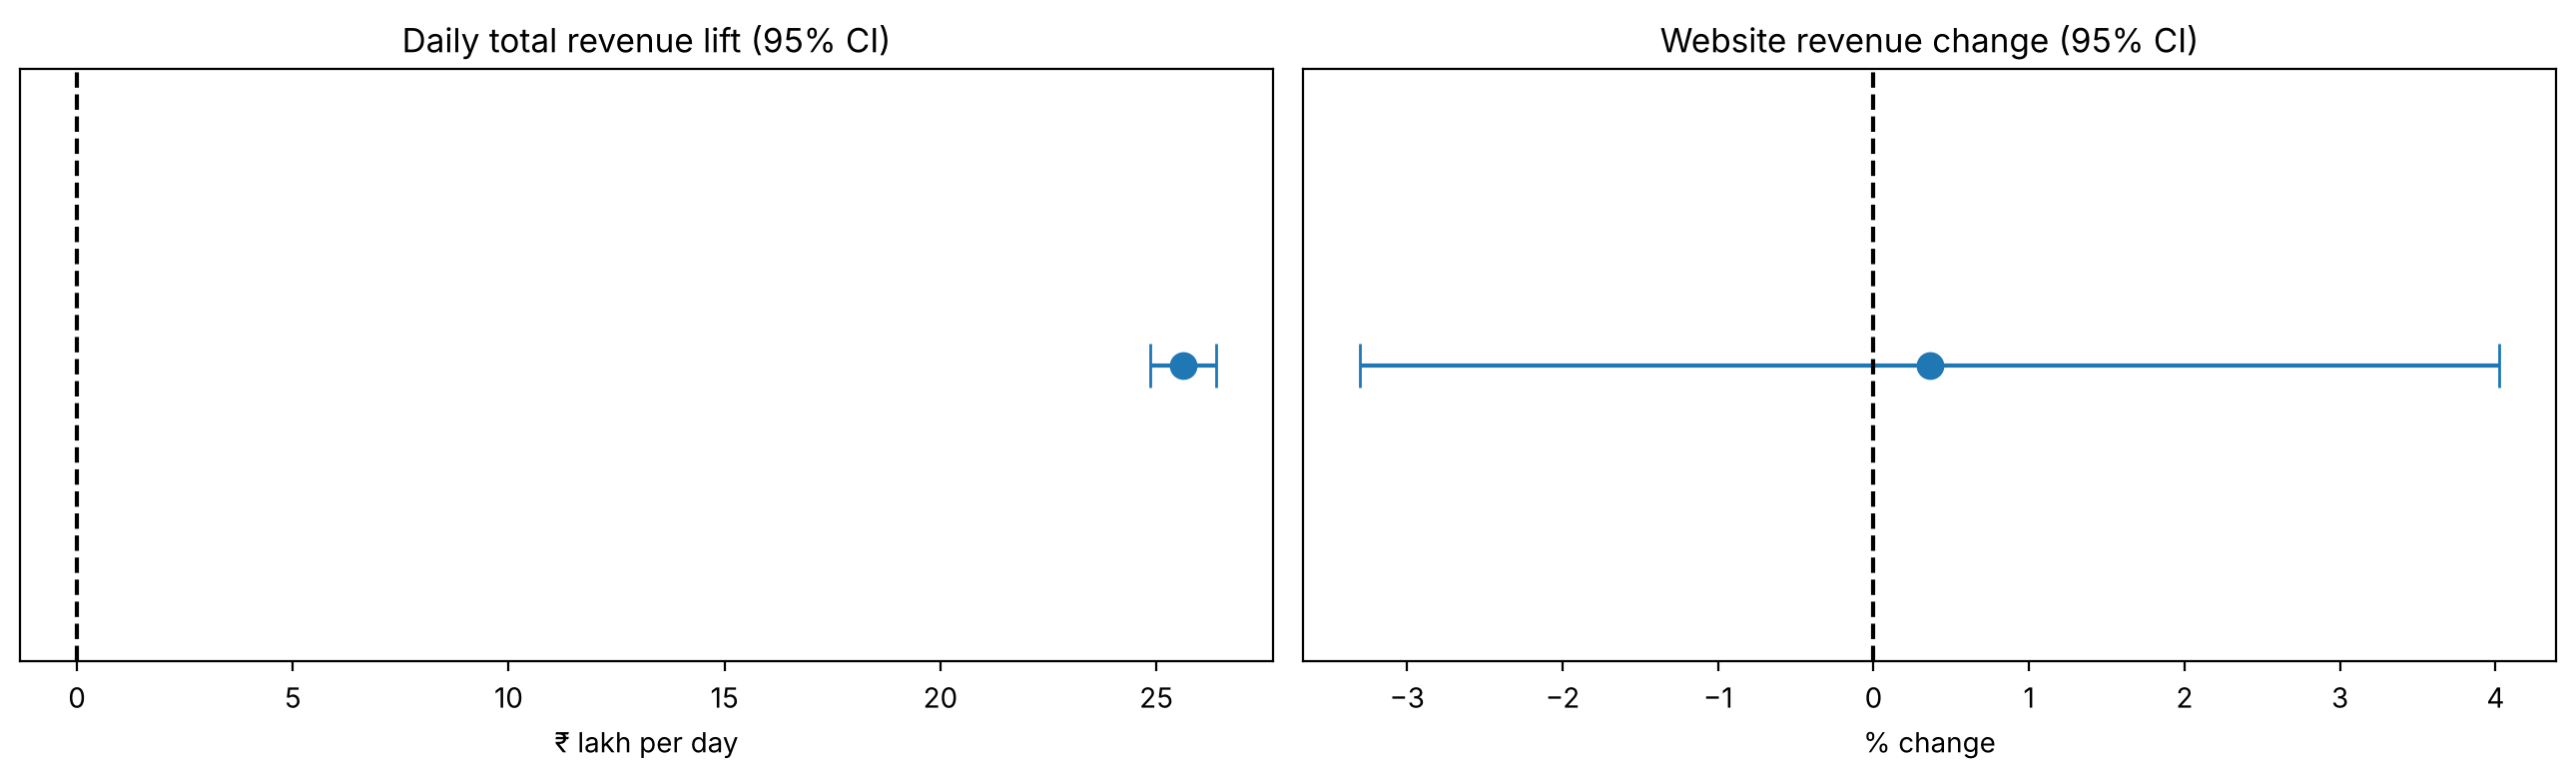

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (val, l, h, title, unit) in zip(ax, [
        (diff / 1e5, lo / 1e5, hi / 1e5, 'Daily total revenue lift', '₹ lakh per day'),
        (d_web / base * 100, lo_web / base * 100, hi_web / base * 100, 'Website revenue change', '% change')]):
    a.errorbar(val, 0, xerr=[[val - l], [h - val]], fmt='o', capsize=8, ms=9)
    a.axvline(0, ls='--', color='black')
    a.set(title=f'{title} (95% CI)', xlabel=unit, yticks=[])
plt.tight_layout(); plt.show()

The total lift sits far above zero, while the website change straddles zero. That one picture is the whole "incremental, not cannibalising" story.

## 9. Regression
Separates the app's effect from promotions, holidays, day of week, campaign type and marketing spend.
- Uses all 4,998 rows.
- `C()` turns categories into dummy variables.
- Standard errors are **clustered by date**, because rows on the same day share that day's conditions.

In [24]:
controls = 'promo_active + is_holiday + C(day_of_week) + C(campaign_type)'

def fit(formula, data=df):
    return smf.ols(formula, data=data).fit(cov_type='cluster', cov_kwds={'groups': data['date']})

m1 = fit(f'total_revenue ~ post + {controls}')
m2 = fit(f'total_revenue ~ post + {controls} + marketing_spend_website')
m3 = fit(f'total_revenue ~ post + {controls} + marketing_spend_website + marketing_spend_app')
m2.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,3.709e+04,1547.373,23.970,0.000,3.41e+04,4.01e+04
C(day_of_week)[T.1],2437.8268,1043.430,2.336,0.019,392.742,4482.911
C(day_of_week)[T.2],4970.4438,1050.546,4.731,0.000,2911.411,7029.476
C(day_of_week)[T.3],7329.5110,1033.700,7.091,0.000,5303.495,9355.527
C(day_of_week)[T.4],8522.9087,1175.156,7.253,0.000,6219.645,1.08e+04
C(day_of_week)[T.5],1.008e+04,1069.757,9.427,0.000,7987.954,1.22e+04
C(day_of_week)[T.6],1.14e+04,937.841,12.158,0.000,9563.755,1.32e+04
C(campaign_type)[T.email],931.7969,1035.366,0.900,0.368,-1097.483,2961.077
C(campaign_type)[T.search],-576.1795,899.434,-0.641,0.522,-2339.037,1186.678
C(campaign_type)[T.social],720.8206,1048.027,0.688,0.492,-1333.275,2774.917


### 9.1 Comparing the models

In [25]:
def post_row(m, name):
    lo_, hi_ = m.conf_int().loc['post']
    return pd.Series({'post_coef (₹/row)': m.params['post'], 'ci_lower': lo_, 'ci_upper': hi_,
                      'post_coef × 42 (₹/day)': m.params['post'] * 42,
                      'p_value': m.pvalues['post'], 'R²': m.rsquared}, name=name)

r2_without_post = smf.ols(f'total_revenue ~ {controls} + marketing_spend_website', data=df).fit().rsquared
print(f'R² without post: {r2_without_post:.3f}  →  with post: {m2.rsquared:.3f}')

pd.DataFrame([post_row(m1, '1. Controls'),
              post_row(m2, '2. + website spend'),
              post_row(m3, '3. + website & app spend')])

R² without post: 0.026  →  with post: 0.647


,post_coef (₹/row),ci_lower,ci_upper,post_coef × 42 (₹/day),p_value,R²
1. Controls,"61,266.50","60,133.12","62,399.88","2,573,193.08",0.00,0.65
2. + website spend,"61,262.07","60,126.47","62,397.68","2,573,007.15",0.00,0.65
3. + website & app spend,"58,218.44","55,265.19","61,171.70","2,445,174.68",0.00,0.65


- The app effect is about **₹61,000 per row**, or **₹25.7 lakh per day** (× 42 rows). That matches the ₹25.6 lakh lift from Section 8, so the controls don't change the story.
- Adding `post` raises R² from **0.03 to 0.65**: the launch explains most of the variation in revenue.
- Website spend is not significant (p ≈ 0.12).

### 9.2 Model 2 or Model 3? (multicollinearity check)

In [26]:
X = sm.add_constant(df[['post', 'marketing_spend_app', 'marketing_spend_website']])
pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
          index=X.columns[1:], name='VIF')

post                      5.26
marketing_spend_app       5.26
marketing_spend_website   1.00
Name: VIF, dtype: float64

In [27]:
print(f"App spend coefficient: {m3.params['marketing_spend_app']:.2f}  (p = {m3.pvalues['marketing_spend_app']:.3f})")

App spend coefficient: 2.44  (p = 0.024)


App spend is 0 for every pre-launch row, so it moves together with `post`. Both have a **VIF of about 5.3**, right at the usual warning level of 5, and the CI for `post` more than doubles in width in Model 3. In Model 3, each extra ₹1 of app spend is linked to about ₹2.4 of extra revenue (p = 0.02), on top of the launch effect itself. **Model 2 is the main model:** it measures the full effect of launching the app, including the app marketing that came with it. Model 3 is a sensitivity check.

### 9.3 Percentage effect (log model)

In [28]:
m_log = fit(f'np.log(total_revenue) ~ post + {controls} + marketing_spend_website')
pct = (np.exp(m_log.params['post']) - 1) * 100
pct_lo, pct_hi = (np.exp(m_log.conf_int().loc['post']) - 1) * 100
print(f"Revenue per row after launch: {pct:+.0f}%  (95% CI {pct_lo:+.0f}% to {pct_hi:+.0f}%)")

Revenue per row after launch: +134%  (95% CI +130% to +139%)


After controls, revenue per row is about **+134%** higher after launch. That is close to the +124% from the simple comparison. The log model is a little higher because it compares the **geometric mean** (the typical row) rather than the arithmetic mean, and the high-value rows pull the arithmetic mean up more before launch.

### 9.4 Cannibalisation, with controls

In [29]:
m_web = fit(f'np.log(website_revenue) ~ post + {controls} + marketing_spend_website')
w = (np.exp(m_web.params['post']) - 1) * 100
w_lo, w_hi = (np.exp(m_web.conf_int().loc['post']) - 1) * 100
print(f"Website revenue after launch: {w:+.1f}%  (95% CI {w_lo:+.1f}% to {w_hi:+.1f}%), p = {m_web.pvalues['post']:.2f}")

Website revenue after launch: +0.5%  (95% CI -1.3% to +2.3%), p = 0.60


Even after controls, website revenue did not change (**+0.5%, CI −1.3% to +2.3%**). This is a tighter result than the simple t-test, and it confirms **no cannibalisation**.

### 9.5 Diagnostics

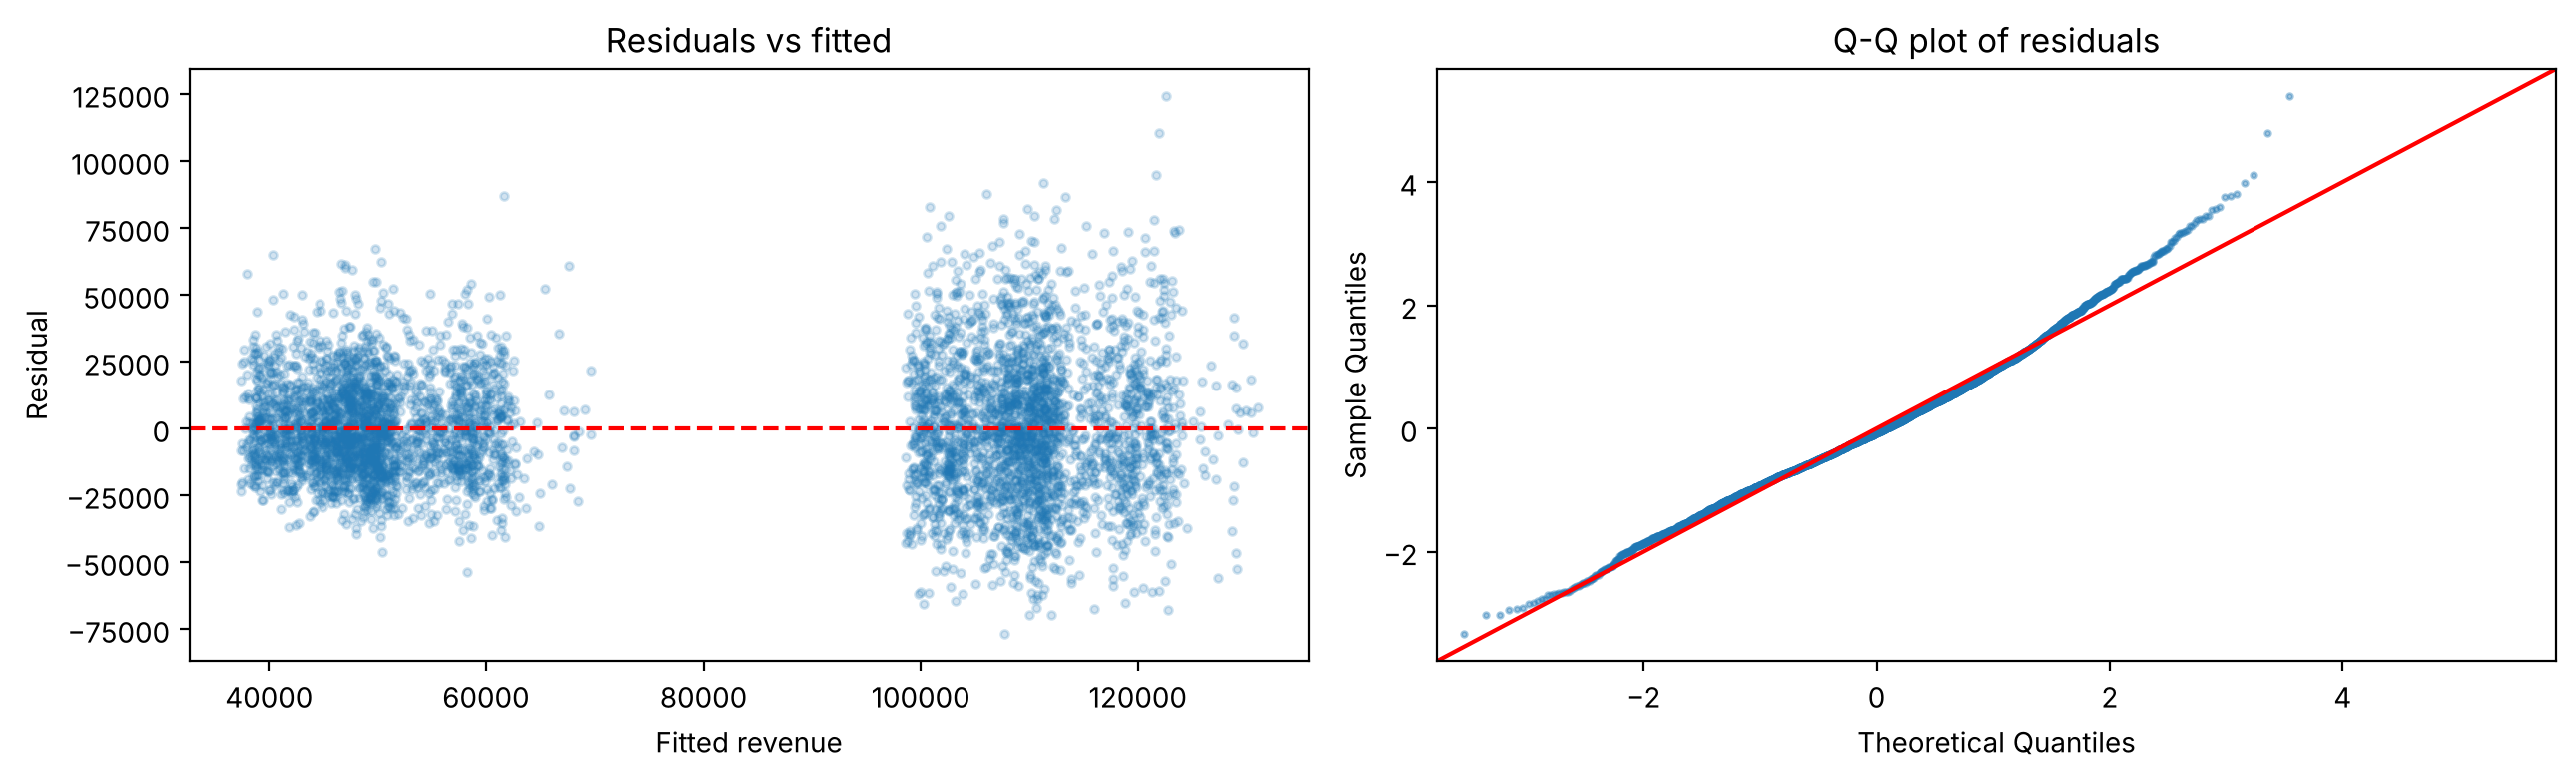

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(m2.fittedvalues, m2.resid, alpha=0.2, s=8)
ax[0].axhline(0, color='red', ls='--')
ax[0].set(title='Residuals vs fitted', xlabel='Fitted revenue', ylabel='Residual')
sm.qqplot(m2.resid, line='45', fit=True, ax=ax[1], markersize=2, alpha=0.4)
ax[1].set_title('Q-Q plot of residuals')
plt.tight_layout(); plt.show()

Residuals are centred on zero, with **two clusters** (pre and post) and a wider spread after launch (heteroscedasticity). The Q-Q plot shows a heavier right tail, from the high-value policies. Clustered standard errors are robust to unequal variance, and the log model reduces the skew, so the conclusions hold.

### 9.6 Robustness: daily-level model

In [31]:
m_daily = smf.ols('total_revenue ~ post + promo_share + holiday_share + C(day_of_week) + marketing_spend_website',
                  data=daily).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
lo_d, hi_d = m_daily.conf_int().loc['post']
print(f"Daily model: post = ₹{m_daily.params['post'] / 1e5:.1f}L per day "
      f"(95% CI ₹{lo_d / 1e5:.1f}L to ₹{hi_d / 1e5:.1f}L), R² = {m_daily.rsquared:.2f}")

Daily model: post = ₹25.7L per day (95% CI ₹25.2L to ₹26.3L), R² = 0.99


Using the 119 daily totals with Newey-West (HAC) standard errors, which allow for correlation between nearby days, gives the **same ₹25–26 lakh per day** effect. The result does not depend on the unit of analysis.

## 10. Is the lift sustained, or just a launch spike?
A spike would show high revenue straight after launch that then fades. A sustained effect stays at the new level.

In [32]:
post_d = daily[daily['period'] == 'Post'].copy()
post_d['week'] = post_d['days_since_launch'] // 7 + 1
weekly = post_d.groupby('week').agg(days=('date', 'size'), total=('total_revenue', 'mean'),
                                    app=('app_revenue', 'mean'), website=('website_revenue', 'mean'))
weekly[['total', 'app', 'website']] /= 1e5
weekly.round(1)   # ₹ lakh per day

,days,total,app,website
week,,,,
1,7,45.60,25.00,20.60
2,7,46.70,25.70,21.00
3,7,46.20,25.60,20.60
4,7,45.50,25.00,20.50
5,7,46.30,26.00,20.30
6,7,46.60,25.80,20.80
7,7,47.50,26.20,21.30
8,7,46.70,25.40,21.30
9,3,44.60,24.70,19.90


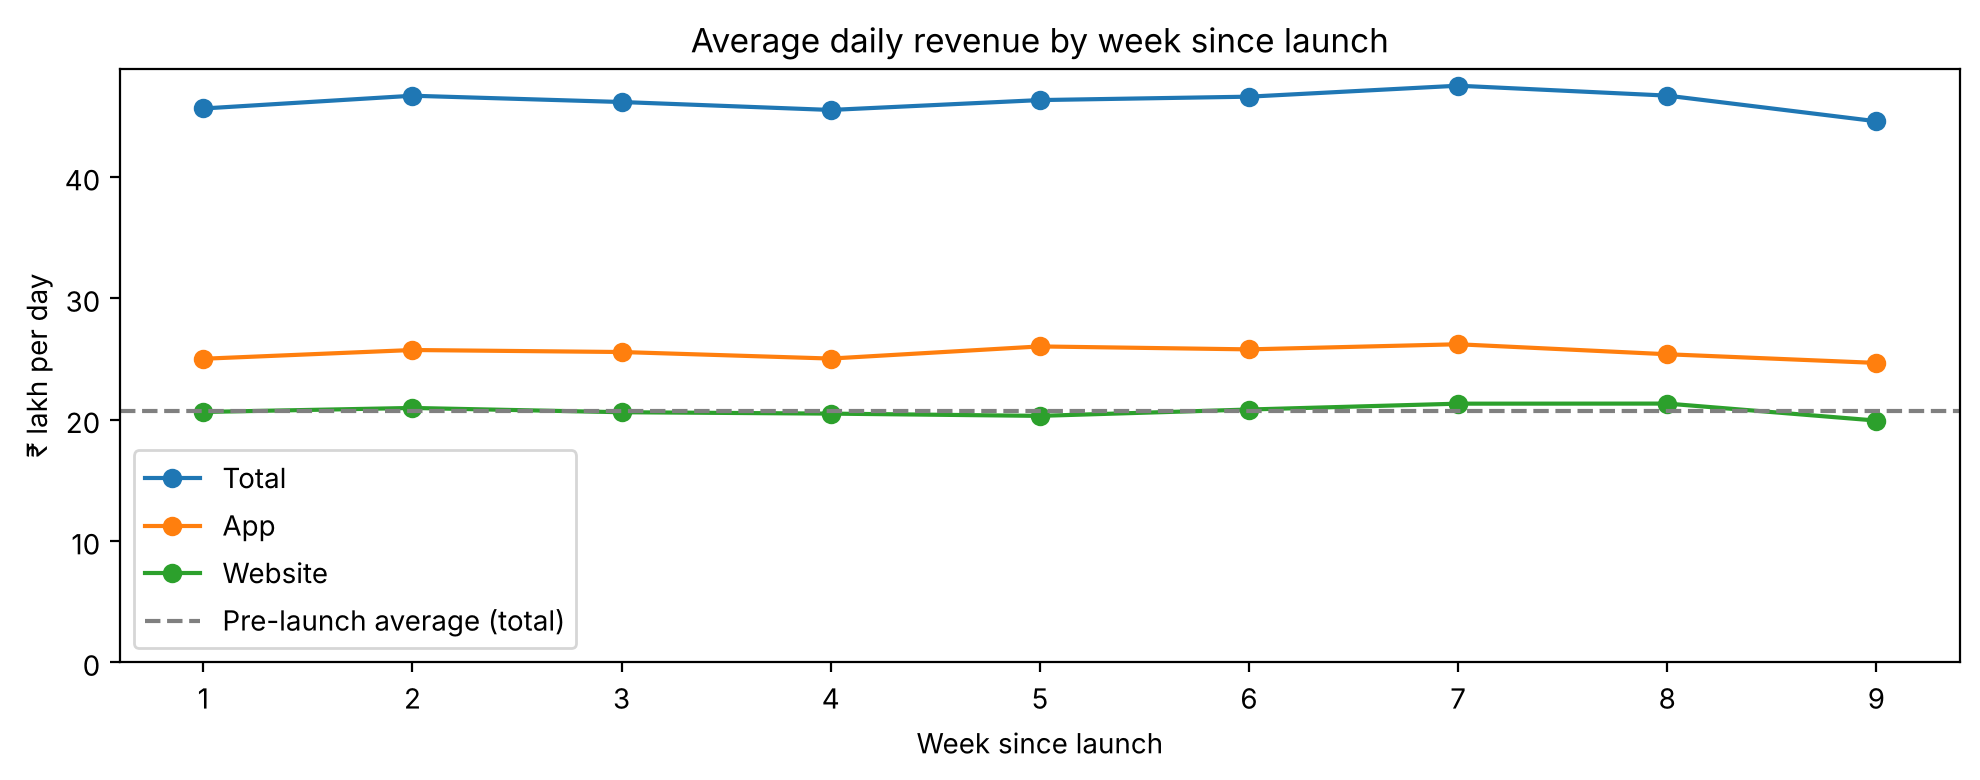

In [33]:
fig, ax = plt.subplots(figsize=(10, 4))
for col in ['total', 'app', 'website']:
    ax.plot(weekly.index, weekly[col], marker='o', label=col.title())
ax.axhline(pre.mean() / 1e5, ls='--', color='grey', label='Pre-launch average (total)')
ax.set(title='Average daily revenue by week since launch', xlabel='Week since launch',
       ylabel='₹ lakh per day', ylim=(0, None))
ax.legend(); plt.tight_layout(); plt.show()

Every week sits at roughly the same level (about ₹46L total, ₹25L from the app). There is no early peak followed by a decline. Week 9 has only 3 days, so it is noisier.

### 10.1 Formal tests

In [34]:
# (a) Trend after launch: does revenue drift up or down over time?
trend = smf.ols('total_revenue ~ days_since_launch + promo_share + holiday_share + C(day_of_week)',
                data=post_d).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
print(f"(a) Post-launch trend: ₹{trend.params['days_since_launch']:,.0f} per day, p = {trend.pvalues['days_since_launch']:.2f}")

# (b) First 30 days vs the remaining 29 days
first, later = post_d.loc[post_d['days_since_launch'] < 30, 'total_revenue'], post_d.loc[post_d['days_since_launch'] >= 30, 'total_revenue']
print(f"(b) First 30 days ₹{first.mean() / 1e5:.1f}L vs last 29 days ₹{later.mean() / 1e5:.1f}L, "
      f"p = {stats.ttest_ind(first, later).pvalue:.2f}")

# (c) March vs April (April is after the tax-saving deadline)
by_month = post_d.groupby(post_d['date'].dt.month_name())[['total_revenue', 'website_revenue', 'app_revenue']].mean() / 1e5
print('\n(c) Average daily revenue by month (₹ lakh):')
print(by_month.round(1))

(a) Post-launch trend: ₹1,326 per day, p = 0.35
(b) First 30 days ₹46.0L vs last 29 days ₹46.6L, p = 0.34

(c) Average daily revenue by month (₹ lakh):
       total_revenue  website_revenue  app_revenue
date                                              
April          46.60            20.90        25.70
March          46.00            20.60        25.40


- **(a)** There is no significant upward or downward trend after launch (p ≈ 0.35).
- **(b)** The first month and the second month are statistically the same (p ≈ 0.34).
- **(c)** April, after the 31 March tax-saving deadline, is as strong as March for both the website and the app. If March tax-season demand had inflated the result, April would have dropped. **This weakens the seasonality concern** raised in Section 6.

### 10.2 Interrupted time series (segmented regression)
A standard method for measuring the effect of an event over time. It fits one model to all 119 days with three parts:
- `days_since_launch`: the trend before launch
- `post`: the **immediate jump** at launch
- `days_since_launch × post`: the **change in trend** after launch

In [35]:
daily['t_after'] = daily['days_since_launch'] * daily['post']
its = smf.ols('total_revenue ~ days_since_launch + post + t_after', data=daily).fit(
    cov_type='HAC', cov_kwds={'maxlags': 7})
pd.DataFrame({'coef': its.params, 'p_value': its.pvalues}).round(3)

,coef,p_value
Intercept,"2,074,551.82",0.00
days_since_launch,207.47,0.79
post,"2,514,090.37",0.00
t_after,"1,214.06",0.51


- **Pre-launch trend:** flat (p ≈ 0.8), so revenue was not already rising before the app.
- **Immediate jump at launch:** about **₹25 lakh per day** (p < 0.001).
- **Change in trend after launch:** not significant (p ≈ 0.5), so the new level neither grows nor decays.

**Verdict: a sustained step-change, not a temporary spike.**

### 10.3 App adoption and engagement over time

In [36]:
eng = df[df['period'] == 'Post'].groupby('date').agg(downloads=('app_downloads', 'sum'),
                                                       active_users=('active_app_users', 'sum'),
                                                       session_min=('app_session_duration_avg', 'mean')).reset_index()
eng['day'] = (eng['date'] - LAUNCH).dt.days
for col in ['downloads', 'active_users', 'session_min']:
    m = smf.ols(f'{col} ~ day', data=eng).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
    print(f"{col:13s} mean {eng[col].mean():8,.1f}   trend per day {m.params['day']:+.2f}   p = {m.pvalues['day']:.2f}")

downloads     mean  2,105.6   trend per day -0.24   p = 0.49
active_users  mean  3,359.6   trend per day +0.01   p = 0.97


session_min   mean      5.0   trend per day +0.00   p = 0.36


Downloads, active users and session length are all **flat** over the 59 days, so engagement is not fading. However, the number of active users is not growing either, even though about 2,100 downloads happen each day. If `active_app_users` counts daily actives, this **may point to a retention gap**: many new users don't keep using the app. The dataset has no user-level data to confirm this, so it is a lead to investigate, not a finding.

## 11. Summary of findings
| Question | Answer |
|---|---|
| Did revenue increase? | **Yes.** +124%, from ₹20.7L to ₹46.3L per day (p < 0.001, Cohen's d ≈ 12). Every post-launch day beat the best pre-launch day. |
| By how much? | **₹25.6L per day** (95% CI ₹24.8L to ₹26.4L), about ₹7.7 Cr per month and ₹93 Cr per year. |
| Is it the app, or other factors? | **The app.** Promotions and holidays were balanced; after controlling for them and for spend, the effect is the same (₹25.7L per day, +134% per row). |
| Did the app take sales from the website? | **No.** Website revenue changed by +0.5% (CI −1.3% to +2.3%). The app's ₹25.5L per day is new revenue. |
| Spike or sustained? | **Sustained.** A step-change at launch with no decay over 59 days; April is as strong as March. |
| Is the app a good marketing channel? | **Yes.** App ROAS is 48.7, versus 29.9 for the website. Conversion rate rose from 4.3% to 5.3%. |

## 12. Recommendations
1. **Keep investing in the app.** It is now the larger channel (55% of revenue), and it adds new revenue rather than shifting existing sales.
2. **Shift marketing budget towards the app.** Each ₹1 there returns about ₹49, versus ₹30 on the website. Increase it step by step and watch for diminishing returns.
3. **Keep the website running as it is.** Its revenue and efficiency were unchanged, which suggests the app is reaching customers the website was not reaching.
4. **Investigate app retention.** About 2,100 people download the app each day, but active users are not growing. Track user cohorts to confirm whether new users drop off; if they do, onboarding, reminders and renewal nudges could turn downloads into lasting revenue.
5. **Fix the data tracking.** `app_crashes` shows values before the app existed. Reliable crash data is needed to monitor app quality.
6. **Re-run this analysis after 6–12 months** to confirm the effect across a full year, including the next tax season.

## 13. Methodology note
- **Tools:** Python (pandas, SciPy, statsmodels) in Google Colab; key results are reproduced in the accompanying Excel file.
- **Data cleaning:** 30 Apr 2025 was dropped (2 of 42 rows); `app_crashes` was excluded as unreliable; outliers (~1%) were kept as real high-value sales.
- **Unit of analysis:** daily totals (n = 119) for tests and confidence intervals; individual rows (n = 4,998) for regression, with standard errors clustered by date.
- **Methods:** descriptive statistics; Shapiro–Wilk and Levene assumption checks; one-tailed Student's and Welch's t-tests; Mann–Whitney U; Cohen's d; two-proportion z-test; 95% confidence intervals; OLS regression with controls (linear and log), VIF check, residual diagnostics; daily regression with Newey-West (HAC) errors; interrupted time series.
- **Limitations:** a before/after design with no control group, so unmeasured events around 2 March cannot be fully ruled out; only 59 days after launch; channel ROAS assumes each channel's spend drives its own revenue; some patterns are unusually clean for real data (e.g. website ROAS is 29.88 both before and after launch), which suggests the dataset may be simulated.

## 14. Export for Excel spot-checks
Saves the daily table and an Excel sheet that recomputes the main results with Excel's own formulas (`T.TEST`, `AVERAGE`, `STDEV.S`). The values should match Sections 7–8.

In [37]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill
from openpyxl.utils.dataframe import dataframe_to_rows

out = daily[['date', 'period', 'post', 'total_revenue', 'website_revenue', 'app_revenue',
             'total_visits', 'total_conversions', 'marketing_spend_website', 'marketing_spend_app',
             'promo_share', 'holiday_share', 'days_since_launch']].sort_values('date').copy()
out['date'] = out['date'].dt.date
n_pre, n_post = (out['period'] == 'Pre').sum(), (out['period'] == 'Post').sum()
assert (out['period'].iloc[:n_pre] == 'Pre').all()        # pre rows come first, then post

wb = Workbook()
ws = wb.active
ws.title = 'daily'
for row in dataframe_to_rows(out, index=False, header=True):
    ws.append(row)
for col in 'DEFIJ':                                       # rupee columns
    for cell in ws[col][1:]:
        cell.number_format = '#,##0.00'
for col in 'KL':
    for cell in ws[col][1:]:
        cell.number_format = '0.00%'
ws['A1'].font = Font(bold=True)
for cell in ws[1]:
    cell.font = Font(bold=True)
ws.column_dimensions['A'].width = 12
ws.freeze_panes = 'A2'

# Cell ranges: pre-launch rows first, then post-launch rows
last = n_pre + n_post + 1
pre_rng,  post_rng  = f'daily!D2:D{n_pre + 1}', f'daily!D{n_pre + 2}:D{last}'
wpre_rng, wpost_rng = f'daily!E2:E{n_pre + 1}', f'daily!E{n_pre + 2}:E{last}'

sp = np.sqrt(((n_pre - 1) * pre.var() + (n_post - 1) * post.var()) / (n_pre + n_post - 2))
se = sp * np.sqrt(1 / n_pre + 1 / n_post)

rows = [  # (label, Excel formula, Python value, notebook section)
    ('Days, pre-launch',            f'=COUNT({pre_rng})',                 n_pre,             '4'),
    ('Days, post-launch',           f'=COUNT({post_rng})',                n_post,            '4'),
    ('Mean daily revenue, pre',     f'=AVERAGE({pre_rng})',               pre.mean(),        '6'),
    ('Mean daily revenue, post',    f'=AVERAGE({post_rng})',              post.mean(),       '6'),
    ('Daily lift (post − pre)',     '=B5-B4',                             diff,              '8.1'),
    ('Lift as % of pre-launch',     '=B6/B4',                             diff / pre.mean(), '8.1'),
    ('Std dev, pre',                f'=_xlfn.STDEV.S({pre_rng})',         pre.std(),         '7'),
    ('Std dev, post',               f'=_xlfn.STDEV.S({post_rng})',        post.std(),        '7'),
    ('Pooled std dev',              '=SQRT(((B2-1)*B8^2+(B3-1)*B9^2)/(B2+B3-2))', sp,        '8.1'),
    ('Standard error of the lift',  '=B10*SQRT(1/B2+1/B3)',               se,                '8.1'),
    ('t critical (95%, two-sided)', '=_xlfn.T.INV.2T(0.05,B2+B3-2)',      stats.t.ppf(0.975, n_pre + n_post - 2), '8.1'),
    ('95% CI lower (₹/day)',        '=B6-B12*B11',                        lo,                '8.1'),
    ('95% CI upper (₹/day)',        '=B6+B12*B11',                        hi,                '8.1'),
    ("Cohen's d",                   '=B6/B10',                            cohens_d(post, pre), '7.2'),
    ("Student's t-test p (one-tailed)",  f'=_xlfn.T.TEST({post_rng},{pre_rng},1,2)',
        stats.ttest_ind(post, pre, alternative='greater').pvalue, '7.2'),
    ('Mean website revenue, pre',   f'=AVERAGE({wpre_rng})',              pre_web.mean(),    '7.3'),
    ('Mean website revenue, post',  f'=AVERAGE({wpost_rng})',             post_web.mean(),   '7.3'),
    ('Website revenue t-test p (two-tailed)', f'=_xlfn.T.TEST({wpost_rng},{wpre_rng},2,2)',
        stats.ttest_ind(post_web, pre_web).pvalue, '7.3'),
]

chk = wb.create_sheet('checks')
chk.append(['Metric', 'Excel formula result', 'Python result', 'Notebook section'])
for label, formula, value, section in rows:
    chk.append([label, formula, float(value), section])

for r in range(2, len(rows) + 2):
    label = chk[f'A{r}'].value
    fmt = ('0.00E+00' if 'p (' in label else '0.00%' if '%' in label
           else '0' if label.startswith('Days') else '0.000' if label.startswith(('t critical', "Cohen")) else '#,##0.00')
    chk[f'B{r}'].number_format = chk[f'C{r}'].number_format = fmt
for cell in chk[1]:
    cell.font = Font(bold=True, color='FFFFFF')
    cell.fill = PatternFill('solid', fgColor='305496')
for col, w in zip('ABCD', [40, 22, 22, 18]):
    chk.column_dimensions[col].width = w
chk['A22'] = 'Column B is calculated by Excel from the daily sheet; column C is the value from the Python notebook. They should match.'
chk['A22'].font = Font(italic=True)

wb.save('app_launch_analysis.xlsx')
print('Saved app_launch_analysis.xlsx')
try:
    files.download('app_launch_analysis.xlsx')   # downloads automatically in Colab
except NameError:
    pass

Saved app_launch_analysis.xlsx
